# Preprocesamiento de Datos de la EPA para años 2023-2025 (3 datasets) per day.


El objetivo de este estudio es caracterizar fuentes de contaminación ambiental para determinar si los tipos contaminantes pueden tener incidencia del tipo de ubicación de las estaciones metereológicas y de calidad del aire. Los datos analizados con EPA, autoridad ambiental en Estados Unidos.

## Importacion de Librerias

In [ ]:
# Importación de librerías
%pip install nolds
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nolds
import requests
import zipfile
import io

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 225.7/225.7 kB 5.7 MB/s eta 0:00:00


## Carga de los datos y materiales

In [ ]:
def leer_zip_aqs(url):
    """
    Descarga un ZIP de la EPA, encuentra el CSV correcto dentro de él
    (ignorando carpetas) y devuelve un DataFrame de Pandas.
    Funciona como un reemplazo directo de pd.read_csv para estos archivos.
    """
    print(f"Leyendo datos desde: {url}")
    try:
        # 1. Descargar el archivo
        response = requests.get(url, timeout=60)
        response.raise_for_status()

        # 2. Abrir el ZIP en memoria
        with zipfile.ZipFile(io.BytesIO(response.content)) as zip_file:
            # Buscar el archivo .csv real (ignorando carpetas)
            csv_file_name = next(
                (name for name in zip_file.namelist() if name.endswith('.csv') and not name.startswith('__')),
                None
            )

            if csv_file_name:
                # 3. Leer y devolver el DataFrame
                with zip_file.open(csv_file_name) as csv_file:
                    return pd.read_csv(csv_file, low_memory=False)
            else:
                raise ValueError("No se encontró un archivo .csv dentro del ZIP descargado.")

    except Exception as e:
        print(f"Error procesando {url}: {e}")
        return None

# ==========================================
# ASIGNACIÓN A VARIABLES Y VERIFICACIÓN
# ==========================================

# Estaciones de Monitoreo
stations= leer_zip_aqs("https://aqs.epa.gov/aqsweb/airdata/aqs_sites.zip")

#----- 2023 -----
# 1. PM2.5 FRM/FEM
pm25_frm_fem_2023 = leer_zip_aqs("https://aqs.epa.gov/aqsweb/airdata/daily_88101_2023.zip")
# 2. PM2.5 non-FRM/FEM
pm25_non_frm_fem_2023 = leer_zip_aqs("https://aqs.epa.gov/aqsweb/airdata/daily_88502_2023.zip")
# 3. PM10
pm10_2023 = leer_zip_aqs("https://aqs.epa.gov/aqsweb/airdata/daily_81102_2023.zip")
# 4. PM Coarse
pmc_2023 = leer_zip_aqs("https://aqs.epa.gov/aqsweb/airdata/daily_86101_2023.zip")

#----- 2024 -----
# 5. PM2.5 FRM/FEM
pm25_frm_fem_2024 = leer_zip_aqs("https://aqs.epa.gov/aqsweb/airdata/daily_88101_2024.zip")
# 6. PM2.5 non-FRM/FEM
pm25_non_frm_fem_2024 = leer_zip_aqs("https://aqs.epa.gov/aqsweb/airdata/daily_88502_2024.zip")
# 7. PM10
pm10_2024 = leer_zip_aqs("https://aqs.epa.gov/aqsweb/airdata/daily_81102_2024.zip")
# 8. PM Coarse
pmc_2024 = leer_zip_aqs("https://aqs.epa.gov/aqsweb/airdata/daily_86101_2024.zip")

# ----- 2025 -----
# 9. PM2.5 FRM/FEM
pm25_frm_fem_2025 = leer_zip_aqs("https://aqs.epa.gov/aqsweb/airdata/daily_88101_2025.zip")
# 10. PM2.5 non-FRM/FEM
pm25_non_frm_fem_2025 = leer_zip_aqs("https://aqs.epa.gov/aqsweb/airdata/daily_88502_2025.zip")
# 11. PM10
pm10_2025 = leer_zip_aqs("https://aqs.epa.gov/aqsweb/airdata/daily_81102_2025.zip")
# 12. PM Coarse
pmc_2025 = leer_zip_aqs("https://aqs.epa.gov/aqsweb/airdata/daily_86101_2025.zip")

# Verificación rápida (opcional)
if pmc_2025 is not None:
    print(f"\nPM Coarse cargado con dimensiones: {pmc_2025.shape}")

Leyendo datos desde: https://aqs.epa.gov/aqsweb/airdata/aqs_sites.zip
Leyendo datos desde: https://aqs.epa.gov/aqsweb/airdata/daily_88101_2023.zip
Leyendo datos desde: https://aqs.epa.gov/aqsweb/airdata/daily_88502_2023.zip
Leyendo datos desde: https://aqs.epa.gov/aqsweb/airdata/daily_81102_2023.zip
Leyendo datos desde: https://aqs.epa.gov/aqsweb/airdata/daily_86101_2023.zip
Leyendo datos desde: https://aqs.epa.gov/aqsweb/airdata/daily_88101_2024.zip
Leyendo datos desde: https://aqs.epa.gov/aqsweb/airdata/daily_88502_2024.zip
Leyendo datos desde: https://aqs.epa.gov/aqsweb/airdata/daily_81102_2024.zip
Leyendo datos desde: https://aqs.epa.gov/aqsweb/airdata/daily_86101_2024.zip
Leyendo datos desde: https://aqs.epa.gov/aqsweb/airdata/daily_88101_2025.zip
Leyendo datos desde: https://aqs.epa.gov/aqsweb/airdata/daily_88502_2025.zip
Leyendo datos desde: https://aqs.epa.gov/aqsweb/airdata/daily_81102_2025.zip
Leyendo datos desde: https://aqs.epa.gov/aqsweb/airdata/daily_86101_2025.zip

PM Co

In [ ]:
pm25_frm_fem_2025

,State Code,County Code,Site Num,Parameter Code,POC,Latitude,Longitude,Datum,Parameter Name,Sample Duration,...,AQI,Method Code,Method Name,Local Site Name,Address,State Name,County Name,City Name,CBSA Name,Date of Last Change
0,1,3,10,88101,3,30.497478,-87.880258,NAD83,PM2.5 - Local Conditions,1 HOUR,...,NaN,209,Met One BAM-1022 Mass Monitor w/ VSCC or TE-PM...,"FAIRHOPE, Alabama","FAIRHOPE HIGH SCHOOL, 1 PIRATE DRIVE, FAIRHOPE...",Alabama,Baldwin,Fairhope,"Daphne-Fairhope-Foley, AL",2026-03-02
1,1,3,10,88101,3,30.497478,-87.880258,NAD83,PM2.5 - Local Conditions,1 HOUR,...,NaN,209,Met One BAM-1022 Mass Monitor w/ VSCC or TE-PM...,"FAIRHOPE, Alabama","FAIRHOPE HIGH SCHOOL, 1 PIRATE DRIVE, FAIRHOPE...",Alabama,Baldwin,Fairhope,"Daphne-Fairhope-Foley, AL",2026-03-02
2,1,3,10,88101,3,30.497478,-87.880258,NAD83,PM2.5 - Local Conditions,1 HOUR,...,NaN,209,Met One BAM-1022 Mass Monitor w/ VSCC or TE-PM...,"FAIRHOPE, Alabama","FAIRHOPE HIGH SCHOOL, 1 PIRATE DRIVE, FAIRHOPE...",Alabama,Baldwin,Fairhope,"Daphne-Fairhope-Foley, AL",2026-03-02
3,1,3,10,88101,3,30.497478,-87.880258,NAD83,PM2.5 - Local Conditions,1 HOUR,...,NaN,209,Met One BAM-1022 Mass Monitor w/ VSCC or TE-PM...,"FAIRHOPE, Alabama","FAIRHOPE HIGH SCHOOL, 1 PIRATE DRIVE, FAIRHOPE...",Alabama,Baldwin,Fairhope,"Daphne-Fairhope-Foley, AL",2026-03-02
4,1,3,10,88101,3,30.497478,-87.880258,NAD83,PM2.5 - Local Conditions,1 HOUR,...,NaN,209,Met One BAM-1022 Mass Monitor w/ VSCC or TE-PM...,"FAIRHOPE, Alabama","FAIRHOPE HIGH SCHOOL, 1 PIRATE DRIVE, FAIRHOPE...",Alabama,Baldwin,Fairhope,"Daphne-Fairhope-Foley, AL",2026-03-02
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
758829,80,26,6,88101,1,31.291293,-110.951513,WGS84,PM2.5 - Local Conditions,24-HR BLK AVG,...,19.0,638,Teledyne T640X at 16.67 LPM w/Network Data Ali...,Nogales Sonora Institute ITN,"Avenida Instituto Tecnologico #911, Granja, 84...",Country Of Mexico,SONORA,Not in a city,NaN,2026-01-23
758830,80,26,6,88101,1,31.291293,-110.951513,WGS84,PM2.5 - Local Conditions,24-HR BLK AVG,...,37.0,638,Teledyne T640X at 16.67 LPM w/Network Data Ali...,Nogales Sonora Institute ITN,"Avenida Instituto Tecnologico #911, Granja, 84...",Country Of Mexico,SONORA,Not in a city,NaN,2026-01-23
758831,80,26,6,88101,1,31.291293,-110.951513,WGS84,PM2.5 - Local Conditions,24-HR BLK AVG,...,54.0,638,Teledyne T640X at 16.67 LPM w/Network Data Ali...,Nogales Sonora Institute ITN,"Avenida Instituto Tecnologico #911, Granja, 84...",Country Of Mexico,SONORA,Not in a city,NaN,2026-01-23
758832,80,26,6,88101,1,31.291293,-110.951513,WGS84,PM2.5 - Local Conditions,24-HR BLK AVG,...,53.0,638,Teledyne T640X at 16.67 LPM w/Network Data Ali...,Nogales Sonora Institute ITN,"Avenida Instituto Tecnologico #911, Granja, 84...",Country Of Mexico,SONORA,Not in a city,NaN,2026-01-23


In [ ]:
# Borramos las variables que no vamos a usar para evitar confusiones
colstodrop=['State Code', 'County Code', 'Site Num', 'Parameter Code', 'POC', 'Datum', 'Parameter Name', 'Pollutant Standard',
            'Units of Measure', 'Event Type','Observation Count', 'Observation Percent', '1st Max Value', '1st Max Hour', 'AQI', 'Method Code',
            'Method Name', 'Local Site Name', 'Address', 'State Name', 'County Name', 'City Name','CBSA Name', 'Date of Last Change']

def limpiar_dataframe(df):

    """
    Elimina las columnas no necesarias de un DataFrame
    dado una lista de columnas a eliminar.
    """

    if df is not None:
        return df.drop(columns=colstodrop, errors='ignore')
    else:
        print("DataFrame es None, no se puede limpiar.")
        return None

# Limpiar los DataFrames

pm25_frm_fem_2023 = limpiar_dataframe(pm25_frm_fem_2023)
pm25_non_frm_fem_2023 = limpiar_dataframe(pm25_non_frm_fem_2023)
pm10_2023 = limpiar_dataframe(pm10_2023)
pmc_2023 = limpiar_dataframe(pmc_2023)

pm25_frm_fem_2024 = limpiar_dataframe(pm25_frm_fem_2024)
pm25_non_frm_fem_2024 = limpiar_dataframe(pm25_non_frm_fem_2024)
pm10_2024 = limpiar_dataframe(pm10_2024)
pmc_2024 = limpiar_dataframe(pmc_2024)

pm25_frm_fem_2025 = limpiar_dataframe(pm25_frm_fem_2025)
pm25_non_frm_fem_2025 = limpiar_dataframe(pm25_non_frm_fem_2025)
pm10_2025 = limpiar_dataframe(pm10_2025)
pmc_2025 = limpiar_dataframe(pmc_2025)

In [ ]:
print(f"\nLas dimensiones de PM2.5 FRM/FEM 2025 después de limpiar son: {pm25_frm_fem_2025.shape}\n y las columnas son: {pm25_frm_fem_2025.columns.tolist()}")



Las dimensiones de PM2.5 FRM/FEM 2025 después de limpiar son: (758834, 5)
 y las columnas son: ['Latitude', 'Longitude', 'Sample Duration', 'Date Local', 'Arithmetic Mean']


## Observacion de cofiguraciones segun estacion de monitoreo

In [ ]:
stations=stations.drop(columns=["Met Site State Code","Met Site County Code",
                                "Met Site Site Number","Met Site Distance","Met Site Direction","GMT Offset",
                                "Owning Agency","Local Site Name","Address","Zip Code","Tribe Name"])
stations=stations[stations["Site Closed Date"].isna()]
stations

,State Code,County Code,Site Number,Latitude,Longitude,Datum,Elevation,Land Use,Location Setting,Site Established Date,Site Closed Date,Met Site Type,State Name,County Name,City Name,CBSA Name,Extraction Date
6,01,3,10,30.497478,-87.880258,NAD83,37.19,COMMERCIAL,SUBURBAN,2000-01-01,NaN,ON-SITE MET EQUIP,Alabama,Baldwin,Fairhope,"Daphne-Fairhope-Foley, AL",2026-06-26
8,01,5,2,31.664302,-85.606175,WGS84,143.26,FOREST,SUBURBAN,2003-10-06,NaN,NaN,Alabama,Barbour,Not in a city,"Eufaula, AL-GA",2026-06-26
9,01,7,1,32.904048,-87.233057,WGS84,445.00,AGRICULTURAL,RURAL,1991-07-15,NaN,NaN,Alabama,Bibb,Centreville (Centerville),"Birmingham-Hoover, AL",2026-06-26
20,01,27,1,33.284928,-85.803608,NAD83,344.42,RESIDENTIAL,RURAL,1991-03-25,NaN,ON-SITE MET EQUIP,Alabama,Clay,Ashland,NaN,2026-06-26
47,01,33,41,34.763700,-87.652807,WGS84,158.00,INDUSTRIAL,SUBURBAN,1983-01-01,NaN,NaN,Alabama,Colbert,Not in a city,"Florence-Muscle Shoals, AL",2026-06-26
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20985,80,26,4,31.279722,-110.941111,WGS84,1189.00,INDUSTRIAL,SUBURBAN,1994-08-24,NaN,NaN,Country Of Mexico,SONORA,Not in a city,NaN,2026-06-26
20987,80,26,6,31.291293,-110.951513,WGS84,1265.00,COMMERCIAL,SUBURBAN,2021-05-01,NaN,NaN,Country Of Mexico,SONORA,Not in a City,NaN,2026-06-26
20989,80,26,8012,32.466389,-114.768611,WGS84,38.00,RESIDENTIAL,URBAN AND CENTER CITY,2006-02-01,NaN,NaN,Country Of Mexico,SONORA,Not in a City,NaN,2026-06-26
20992,CC,11,1,49.145602,-103.091252,WGS84,567.00,AGRICULTURAL,RURAL,2000-04-06,NaN,OTHER AIRS SITE,Canada,Saskatchewan,Not in a city,NaN,2026-06-26


### Tipos de Estaciones y conteo
- Segun el uso del suelo.
- Segun el tipo de lugar.

In [ ]:
# Se contabilizan las estaciones segun el uso del suelo en el que se encuentran
stations["Land Use"].value_counts()

,count
Land Use,
RESIDENTIAL,1658
COMMERCIAL,1099
INDUSTRIAL,715
AGRICULTURAL,595
FOREST,441
DESERT,104
MOBILE,69
UNKNOWN,21
MILITARY RESERVATION,13


In [ ]:
# Ahora, se contabilizan las mismas estaciones, esta vez, segun el tipo de lugar donde se encuentran
stations["Location Setting"].value_counts()

,count
Location Setting,
RURAL,1849
SUBURBAN,1620
URBAN AND CENTER CITY,1246
UNKNOWN,13


In [ ]:
# Tipo de Estación Meteorológica y conteo
stations["Met Site Type"].value_counts()

,count
Met Site Type,
ON-SITE MET EQUIP,700
OTHER AIRS SITE,242
OTHER,36
AIRPORT,30
NWS,19
ON-SITE UA MET,6


In [ ]:
## ============================================================
## CLASIFICACIÓN DE ESTACIONES POR LAND USE Y LOCATION SETTING
## ============================================================

# Tipos de Land Use a considerar y su letra inicial
land_use_map = {
    "RESIDENTIAL":          "R",
    "INDUSTRIAL":           "I",
    "DESERT":               "D",
    "FOREST":               "F",
    "COMMERCIAL":           "C",
    "MILITARY RESERVATION": "M",
}

# Location Settings válidos
valid_location_settings = ["RURAL", "SUBURBAN", "URBAN AND CENTER CITY"]

# --- Filtrado ---
stations_filtered = stations[
    stations["Land Use"].str.upper().isin(land_use_map.keys()) &
    stations["Location Setting"].str.upper().isin(valid_location_settings)
].copy()

# --- Ordenamiento: primero por Land Use, luego por Latitud y Longitud ---
stations_filtered["_land_use_upper"] = stations_filtered["Land Use"].str.upper()

stations_filtered = stations_filtered.sort_values(
    by=["_land_use_upper", "Latitude", "Longitude"]
).reset_index(drop=True)

# --- Generación del Station ID (R1, R2 … I1, I2 …) ---
stations_filtered["_prefix"] = stations_filtered["_land_use_upper"].map(land_use_map)
stations_filtered["_rank"]   = stations_filtered.groupby("_land_use_upper").cumcount() + 1
stations_filtered["Station ID"] = stations_filtered["_prefix"] + stations_filtered["_rank"].astype(str)


# --- Dataset final ---
station_dataset = stations_filtered[[
    "Station ID",
    "Land Use",
    "Location Setting",
    "Latitude",
    "Longitude"
]].reset_index(drop=True)

# --- Vista previa y resúmenes ---
print("=== Dataset de Estaciones Clasificadas ===")
print(f"Total de estaciones: {len(station_dataset)}\n")
print(station_dataset.head(20).to_string(index=False))

print("\n--- Conteo por Land Use ---")
print(station_dataset.groupby("Land Use").size().rename("Count").to_string())

print("\n--- Conteo por Land Use x Location Setting (subgrupos) ---")
print(
    station_dataset
    .groupby(["Land Use", "Location Setting"])
    .size()
    .rename("Count")
    .to_string()
)

=== Dataset de Estaciones Clasificadas ===
Total de estaciones: 4029

Station ID   Land Use      Location Setting  Latitude   Longitude
        C1 COMMERCIAL URBAN AND CENTER CITY  0.000000    0.000000
        C2 COMMERCIAL                 RURAL 17.955378  -66.162122
        C3 COMMERCIAL                 RURAL 17.967309  -66.186149
        C4 COMMERCIAL URBAN AND CENTER CITY 18.011354  -66.606284
        C5 COMMERCIAL URBAN AND CENTER CITY 18.150240  -65.442103
        C6 COMMERCIAL URBAN AND CENTER CITY 18.343811  -64.931389
        C7 COMMERCIAL URBAN AND CENTER CITY 18.399947  -66.045999
        C8 COMMERCIAL URBAN AND CENTER CITY 18.440774  -66.126531
        C9 COMMERCIAL URBAN AND CENTER CITY 18.445223  -66.067110
       C10 COMMERCIAL URBAN AND CENTER CITY 18.449814  -66.052510
       C11 COMMERCIAL              SUBURBAN 18.453389  -66.694987
       C12 COMMERCIAL URBAN AND CENTER CITY 18.463148  -66.266131
       C13 COMMERCIAL URBAN AND CENTER CITY 18.466760  -66.112793
      

In [ ]:
station_dataset
# station_dataset.to_csv("station_dataset.csv", index=False ) --> Opcional como tabla con info por estación

,Station ID,Land Use,Location Setting,Latitude,Longitude
0,C1,COMMERCIAL,URBAN AND CENTER CITY,0.000000,0.000000
1,C2,COMMERCIAL,RURAL,17.955378,-66.162122
2,C3,COMMERCIAL,RURAL,17.967309,-66.186149
3,C4,COMMERCIAL,URBAN AND CENTER CITY,18.011354,-66.606284
4,C5,COMMERCIAL,URBAN AND CENTER CITY,18.150240,-65.442103
...,...,...,...,...,...
4024,R1654,RESIDENTIAL,SUBURBAN,64.845281,-147.683903
4025,R1655,RESIDENTIAL,SUBURBAN,64.845930,-147.693270
4026,R1656,RESIDENTIAL,SUBURBAN,64.846506,-147.692461
4027,R1657,RESIDENTIAL,SUBURBAN,64.861023,-147.785690


In [ ]:
# Ver todos los Location Settings presentes en el station_dataset (ya filtrado por Land Use)
print(station_dataset["Location Setting"].value_counts())

Location Setting
SUBURBAN                 1563
RURAL                    1266
URBAN AND CENTER CITY    1200
Name: count, dtype: int64


In [ ]:
# Ver combinaciones reales Land Use x Location Setting
station_dataset.groupby(["Land Use", "Location Setting"]).size()

Land Use              Location Setting     
COMMERCIAL            RURAL                    128
                      SUBURBAN                 384
                      URBAN AND CENTER CITY    587
DESERT                RURAL                    102
                      SUBURBAN                   1
                      URBAN AND CENTER CITY      1
FOREST                RURAL                    433
                      SUBURBAN                   7
INDUSTRIAL            RURAL                    294
                      SUBURBAN                 230
                      URBAN AND CENTER CITY    191
MILITARY RESERVATION  RURAL                      4
                      SUBURBAN                   7
                      URBAN AND CENTER CITY      2
RESIDENTIAL           RURAL                    305
                      SUBURBAN                 934
                      URBAN AND CENTER CITY    419
dtype: int64

In [ ]:
# .unstack() mueve el 'Location Setting' a las columnas
# fill_value=0 rellena con 0 donde no haya datos en esa combinación
tabla_matriz = station_dataset.groupby(["Land Use", "Location Setting"]).size().unstack(fill_value=0)

# Mostrar la tabla
display(tabla_matriz)


Location Setting,RURAL,SUBURBAN,URBAN AND CENTER CITY
Land Use,,,
COMMERCIAL,128,384,587
DESERT,102,1,1
FOREST,433,7,0
INDUSTRIAL,294,230,191
MILITARY RESERVATION,4,7,2
RESIDENTIAL,305,934,419


## Definicion de Estaciones Meteorologicas

In [ ]:
## ============================================================
## VALIDACIÓN DE OBSERVACIONES Y ASIGNACIÓN DE ESTACIÓN METEOROLÓGICA
## ============================================================

# --- Función para asignar estación meteorológica ---
def get_met_season(month):
    """
    Estaciones meteorológicas estándar (convencion climatológica):
    DJF = Diciembre, Enero, Febrero    → Invierno
    MAM = Marzo, Abril, Mayo           → Primavera
    JJA = Junio, Julio, Agosto         → Verano
    SON = Septiembre, Octubre, Noviembre → Otoño
    """
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Spring"
    elif month in [6, 7, 8]:
        return "Summer"
    else:
        return "Fall"


## Fijamos el numero de observaciones
- La idea es que #OBS > 0.75 * 1906 dias reales
- De los datos totales (sumando todo lo que obtenido en 3 años 2023-2025) contando que 2024 fue bisiesto

In [ ]:
# --- Parámetros ---
TOTAL_DAYS = 365 + 366 + 365  # 2023 + 2024 (bisiesto) + 2025 = 1096 días reales
THRESHOLD  = 0.75 * TOTAL_DAYS  # 822 observaciones mínimas

print(f"Días reales en el período 2023-2025: {TOTAL_DAYS}")
print(f"Umbral de observaciones (75%):        {THRESHOLD:.0f}\n")

# --- Listas de dataframes por contaminante ---
all_dfs = {
    "PM2.5 FRM/FEM":     [pm25_frm_fem_2023,     pm25_frm_fem_2024,     pm25_frm_fem_2025],
    "PM2.5 non-FRM/FEM": [pm25_non_frm_fem_2023, pm25_non_frm_fem_2024, pm25_non_frm_fem_2025],
    "PM10":              [pm10_2023,             pm10_2024,             pm10_2025],
    "PM Coarse":         [pmc_2023,              pmc_2024,              pmc_2025],
}

# --- Diccionarios de salida ---
valid_sites_per_pollutant = {}   # {contaminante: set de coordenadas válidas (lat, lon)}
consolidated_dfs          = {}   # {contaminante: DataFrame limpio con estación meteorológica}

for name, dfs in all_dfs.items():

    # 1. Concatenar años
    df = pd.concat([d for d in dfs if d is not None], ignore_index=True)

    # 2. Parsear fecha
    df["Date Local"] = pd.to_datetime(df["Date Local"], format="mixed")

    # 3. Contar observaciones por estación (usando Latitude y Longitude directamente)
    obs_count   = df.groupby(["Latitude", "Longitude"]).size()
    valid_sites = set(obs_count[obs_count >= THRESHOLD].index)
    valid_sites_per_pollutant[name] = valid_sites

    # 4. Filtrar solo estaciones válidas
    df = df[df.set_index(["Latitude", "Longitude"]).index.isin(valid_sites)].copy()

    # 5. Asignar estación meteorológica
    df["season"] = df["Date Local"].dt.month.map(get_met_season)

    # 6. Guardar
    consolidated_dfs[name] = df

    print(f"[{name}]")
    print(f"  Estaciones totales:  {obs_count.shape[0]:>6,}")
    print(f"  Estaciones válidas:  {len(valid_sites):>6,}  (>= {THRESHOLD:.0f} obs)")
    print(f"  Registros finales:   {len(df):>6,}")
    print(f"  Distribución por estación meteorológica:")
    print(df["season"].value_counts().to_string())
    print()

Días reales en el período 2023-2025: 1096
Umbral de observaciones (75%):        822

[PM2.5 FRM/FEM]
  Estaciones totales:   1,099
  Estaciones válidas:     938  (>= 822 obs)
  Registros finales:   2,283,334
  Distribución por estación meteorológica:
season
Spring    594575
Summer    578113
Winter    562925
Fall      547721

[PM2.5 non-FRM/FEM]
  Estaciones totales:     419
  Estaciones válidas:     217  (>= 822 obs)
  Registros finales:   426,581
  Distribución por estación meteorológica:
season
Spring    109514
Summer    106808
Winter    106132
Fall      104127

[PM10]
  Estaciones totales:     676
  Estaciones válidas:     449  (>= 822 obs)
  Registros finales:   483,939
  Distribución por estación meteorológica:
season
Summer    121796
Spring    121770
Fall      121298
Winter    119075

[PM Coarse]
  Estaciones totales:     286
  Estaciones válidas:      97  (>= 822 obs)
  Registros finales:   110,088
  Distribución por estación meteorológica:
season
Spring    27994
Summer    27959

In [ ]:
# Ver cuántas estaciones válidas son comunes entre contaminantes
sets = {name: valid_sites_per_pollutant[name] for name in valid_sites_per_pollutant}

station_coords = set(zip(station_dataset["Latitude"], station_dataset["Longitude"]))

for name, s in sets.items():
    in_station_dataset = s & station_coords
    print(f"[{name}] válidas: {len(s):>4} | en station_dataset: {len(in_station_dataset):>4}")

[PM2.5 FRM/FEM] válidas:  938 | en station_dataset:  806
[PM2.5 non-FRM/FEM] válidas:  217 | en station_dataset:  190
[PM10] válidas:  449 | en station_dataset:  399
[PM Coarse] válidas:   97 | en station_dataset:   86


In [ ]:
# Estaciones que tienen los 4 contaminantes Y están en station_dataset
station_coords = set(zip(station_dataset["Latitude"], station_dataset["Longitude"]))

sets_in_sd = {
    name: valid_sites_per_pollutant[name] & station_coords
    for name in valid_sites_per_pollutant
}

estaciones_4 = (
    sets_in_sd["PM2.5 FRM/FEM"]     &
    sets_in_sd["PM2.5 non-FRM/FEM"] &
    sets_in_sd["PM10"]               &
    sets_in_sd["PM Coarse"]
)

estaciones_3_sin_coarse = (
    sets_in_sd["PM2.5 FRM/FEM"]     &
    sets_in_sd["PM2.5 non-FRM/FEM"] &
    sets_in_sd["PM10"]
)

print(f"Estaciones con los 4 contaminantes:          {len(estaciones_4):>4}")
print(f"Estaciones con PM2.5 FRM + non-FRM + PM10:  {len(estaciones_3_sin_coarse):>4}")

Estaciones con los 4 contaminantes:             1
Estaciones con PM2.5 FRM + non-FRM + PM10:     7


### Diseño de la tabla Metadata (datos por estación concatenados)
Esta tabla nos ayudara como una especie de transicion entre los datos crudos y los que finalmente vamos a usar.

Aqui se mostraran datos desde:
- Date Local
- Station ID
- Land Use
- Location Setting
- season
- Pollutant
- Arithmetic Mean

In [ ]:
## ============================================================
## TABLA DE METADATOS CONSOLIDADA (todos los contaminantes)
## ============================================================

# Columnas que nos interesan de cada consolidated_df
cols_needed = ["Date Local", "Latitude", "Longitude", "Arithmetic Mean", "season"]

# Agregar columna de contaminante y concatenar todos
meta_dfs = []

for name, df in consolidated_dfs.items():
    temp = df[cols_needed].copy()
    temp["Pollutant"] = name
    meta_dfs.append(temp)

metadata_table = pd.concat(meta_dfs, ignore_index=True)

# --- Cruce con station_dataset para agregar Station ID, Land Use, Location Setting ---
metadata_table = metadata_table.merge(
    station_dataset[["Latitude", "Longitude", "Station ID", "Land Use", "Location Setting"]],
    on=["Latitude", "Longitude"],
    how="inner"
)

# --- Orden de columnas ---
metadata_table = metadata_table[[
    "Date Local",
    "Station ID",
    "Land Use",
    "Location Setting",
    "season",
    "Pollutant",
    "Arithmetic Mean",
]].sort_values(["Pollutant", "Station ID", "Date Local"]).reset_index(drop=True)

# --- Vista previa ---
print("=== Tabla de Metadatos Consolidada ===")
print(f"Total de registros: {len(metadata_table):,}")
print(f"Estaciones únicas:  {metadata_table['Station ID'].nunique():,}")
print(f"Rango de fechas:    {metadata_table['Date Local'].min()} → {metadata_table['Date Local'].max()}")
print(f"\nConteo por contaminante:")
print(metadata_table.groupby("Pollutant").size().rename("Registros").to_string())
print(f"\nConteo por Land Use x Location Setting:")
print(metadata_table.groupby(["Land Use", "Location Setting"]).size().rename("Registros").to_string())
print(f"\nPrimeras filas:")
print(metadata_table.head(10).to_string(index=False))

=== Tabla de Metadatos Consolidada ===
Total de registros: 2,889,704
Estaciones únicas:  1,104
Rango de fechas:    2023-01-01 00:00:00 → 2025-12-31 00:00:00

Conteo por contaminante:
Pollutant
PM Coarse              97065
PM10                  430587
PM2.5 FRM/FEM        1991275
PM2.5 non-FRM/FEM     370777

Conteo por Land Use x Location Setting:
Land Use              Location Setting     
COMMERCIAL            RURAL                     93887
                      SUBURBAN                 329654
                      URBAN AND CENTER CITY    501161
DESERT                RURAL                     41423
                      SUBURBAN                   2149
                      URBAN AND CENTER CITY      3234
FOREST                RURAL                     92713
                      SUBURBAN                   2972
INDUSTRIAL            RURAL                     96255
                      SUBURBAN                 121529
                      URBAN AND CENTER CITY     92374
MILITARY RES

In [ ]:
metadata_table.head(10)
#metadata_table.to_csv("metadata_table.csv", index=False) --> Te puedes descargar esta tabla para el nuevo nb.

,Date Local,Station ID,Land Use,Location Setting,season,Pollutant,Arithmetic Mean
0,2023-01-01,C121,COMMERCIAL,URBAN AND CENTER CITY,Winter,PM Coarse,6.933333
1,2023-01-02,C121,COMMERCIAL,URBAN AND CENTER CITY,Winter,PM Coarse,8.641667
2,2023-01-03,C121,COMMERCIAL,URBAN AND CENTER CITY,Winter,PM Coarse,8.920833
3,2023-01-04,C121,COMMERCIAL,URBAN AND CENTER CITY,Winter,PM Coarse,10.466667
4,2023-01-05,C121,COMMERCIAL,URBAN AND CENTER CITY,Winter,PM Coarse,13.173913
5,2023-01-06,C121,COMMERCIAL,URBAN AND CENTER CITY,Winter,PM Coarse,12.034783
6,2023-01-07,C121,COMMERCIAL,URBAN AND CENTER CITY,Winter,PM Coarse,10.704167
7,2023-01-08,C121,COMMERCIAL,URBAN AND CENTER CITY,Winter,PM Coarse,7.220833
8,2023-01-09,C121,COMMERCIAL,URBAN AND CENTER CITY,Winter,PM Coarse,10.104167
9,2023-01-10,C121,COMMERCIAL,URBAN AND CENTER CITY,Winter,PM Coarse,8.683333


## Para el nuevo Nb
- La idea es que se haga la tabla que tiene como filas de el datetime y como columnas las son el station identifier.

In [ ]:
## ============================================================
## TABLAS PIVOTE POR CONTAMINANTE
## ============================================================

pollutants = metadata_table["Pollutant"].unique()
pivot_tables = {}

for pollutant in pollutants:
    pivot = (
        metadata_table[metadata_table["Pollutant"] == pollutant]
        .pivot_table(
            index="Date Local",
            columns="Station ID",
            values="Arithmetic Mean",
            aggfunc="mean"  # por si hay duplicados en alguna fecha/estación
        )
    )
    pivot.columns.name = None  # limpiar el nombre del eje de columnas
    pivot.index.name = "Date Local"
    pivot_tables[pollutant] = pivot

    print(f"[{pollutant}]")
    print(f"  Fechas:    {len(pivot):,}")
    print(f"  Estaciones: {pivot.shape[1]:,}")
    print(f"  NaNs:       {pivot.isna().sum().sum():,} ({pivot.isna().mean().mean()*100:.1f}% del total)")
    print()

[PM Coarse]
  Fechas:    1,096
  Estaciones: 86
  NaNs:       4,141 (4.4% del total)

[PM10]
  Fechas:    1,096
  Estaciones: 399
  NaNs:       21,325 (4.9% del total)

[PM2.5 FRM/FEM]
  Fechas:    1,096
  Estaciones: 808
  NaNs:       72,918 (8.2% del total)

[PM2.5 non-FRM/FEM]
  Fechas:    1,096
  Estaciones: 190
  NaNs:       26,787 (12.9% del total)



## Tablas finales limpias por contaminante
Estas tablas se construyen **usando los datos ya filtrados y limpios** (`metadata_table`) de los bloques anteriores.

Formato de cada tabla:
- Primera columna: `Date Local`
- Desde la segunda columna: `Station ID` (ejemplo: `C120`, `C121`, `C122`, ...)
- Cada fila: para cada fecha, el `Arithmetic Mean` de cada estación

Se crean 4 tablas:
- PM Coarse
- PM10
- PM2.5 FRM/FEM
- PM2.5 non-FRM/FEM

In [ ]:
## ============================================================
## TABLAS FINALES (Date Local x Station ID) POR CONTAMINANTE
## ============================================================

# Contaminantes solicitados por el usuario
pollutants_target = [
    "PM Coarse",
    "PM10",
    "PM2.5 FRM/FEM",
    "PM2.5 non-FRM/FEM",
]


def sort_station_ids(ids):
    """Orden natural de Station ID: prefijo + numero (C2 antes de C10)."""
    return sorted(ids, key=lambda x: (x[0], int(x[1:]) if str(x)[1:].isdigit() else 10**9))


final_tables = {}

for pollutant in pollutants_target:
    temp = metadata_table[metadata_table["Pollutant"] == pollutant].copy()

    # Matriz fecha x estacion con Arithmetic Mean
    table = temp.pivot_table(
        index="Date Local",
        columns="Station ID",
        values="Arithmetic Mean",
        aggfunc="mean",
    )

    # Ordenar columnas por Station ID y pasar Date Local a primera columna
    ordered_cols = sort_station_ids(table.columns.tolist())
    table = table.reindex(columns=ordered_cols).reset_index()

    final_tables[pollutant] = table

    print(f"[{pollutant}]")
    print(f"  Filas (fechas):      {len(table):,}")
    print(f"  Columnas totales:    {table.shape[1]:,} (1 de fecha + {table.shape[1]-1:,} estaciones)")
    print(f"  Rango de fechas:     {table['Date Local'].min()} -> {table['Date Local'].max()}")
    print(f"  Ejemplo columnas:    {table.columns[:6].tolist()} ...")
    print()

# Variables directas para usar en el nuevo notebook o exportar
pm_coarse_table = final_tables["PM Coarse"]
pm10_table = final_tables["PM10"]
pm25_frm_fem_table = final_tables["PM2.5 FRM/FEM"]
pm25_non_frm_fem_table = final_tables["PM2.5 non-FRM/FEM"]

[PM Coarse]
  Filas (fechas):      1,096
  Columnas totales:    87 (1 de fecha + 86 estaciones)
  Rango de fechas:     2023-01-01 00:00:00 -> 2025-12-31 00:00:00
  Ejemplo columnas:    ['Date Local', 'C19', 'C121', 'C146', 'C162', 'C202'] ...

[PM10]
  Filas (fechas):      1,096
  Columnas totales:    400 (1 de fecha + 399 estaciones)
  Rango de fechas:     2023-01-01 00:00:00 -> 2025-12-31 00:00:00
  Ejemplo columnas:    ['Date Local', 'C18', 'C19', 'C23', 'C38', 'C42'] ...

[PM2.5 FRM/FEM]
  Filas (fechas):      1,096
  Columnas totales:    809 (1 de fecha + 808 estaciones)
  Rango de fechas:     2023-01-01 00:00:00 -> 2025-12-31 00:00:00
  Ejemplo columnas:    ['Date Local', 'C14', 'C15', 'C17', 'C18', 'C19'] ...

[PM2.5 non-FRM/FEM]
  Filas (fechas):      1,096
  Columnas totales:    191 (1 de fecha + 190 estaciones)
  Rango de fechas:     2023-01-01 00:00:00 -> 2025-12-31 00:00:00
  Ejemplo columnas:    ['Date Local', 'C34', 'C50', 'C69', 'C100', 'C104'] ...



In [ ]:
# Vista rapida de las 4 tablas finales
print("PM Coarse")
display(pm_coarse_table.head())

print("PM10")
display(pm10_table.head())

print("PM2.5 FRM/FEM")
display(pm25_frm_fem_table.head())

print("PM2.5 non-FRM/FEM")
display(pm25_non_frm_fem_table.head())

PM Coarse


Station ID,Date Local,C19,C121,C146,C162,C202,C232,C236,C244,C317,...,R1104,R1127,R1181,R1207,R1264,R1279,R1283,R1284,R1291,R1526
0,2023-01-01,5.445833,6.933333,7.452174,5.091667,13.262500,1.916667,4.650000,5.666667,3.770833,...,5.791667,2.875000,2.875000,7.670833,NaN,6.041667,4.991667,2.225000,5.495833,5.341667
1,2023-01-02,5.295833,8.641667,-3.825000,5.650000,15.729167,2.362500,4.678261,7.341667,3.325000,...,2.708333,5.883333,7.208333,4.620833,NaN,5.033333,5.120833,3.729167,4.758333,9.237500
2,2023-01-03,7.500000,8.920833,-4.200000,7.700000,6.258333,3.836364,10.583333,5.289583,3.497917,...,-0.875000,5.366667,4.879167,2.608333,1.388889,4.270833,4.508333,6.720833,5.204167,7.317391
3,2023-01-04,3.362500,10.466667,0.895238,13.926087,5.258333,2.091667,17.109524,11.704348,5.545833,...,-0.250000,6.033333,7.233333,2.858333,3.045833,3.075000,2.891667,4.483333,3.183333,14.895833
4,2023-01-05,6.204348,13.173913,17.321739,8.462500,6.066667,5.745833,20.733333,9.510000,4.900000,...,3.750000,3.062500,2.908333,2.220833,0.779167,3.429167,2.450000,2.033333,3.875000,9.904167


PM10


Station ID,Date Local,C18,C19,C23,C38,C42,C63,C71,C101,C104,...,R1498,R1526,R1527,R1564,R1569,R1574,R1605,R1613,R1619,R1625
0,2023-01-01,24.0,11.0,27.0,19.0,15.0,21.0,12.0,13.0,8.0,...,4.0,25.0,23.0,25.0,19.0,18.0,12.0,14.0,3.0,13.0
1,2023-01-02,7.0,7.0,18.0,13.0,14.0,11.0,10.0,13.0,7.0,...,2.0,30.0,12.0,10.0,18.0,16.0,6.0,6.0,2.0,11.0
2,2023-01-03,6.0,10.0,15.0,13.0,11.0,14.0,14.0,10.0,18.0,...,5.0,28.0,22.0,7.0,37.0,13.0,7.0,22.0,11.0,7.0
3,2023-01-04,5.0,4.0,15.0,14.0,11.0,15.0,13.0,13.0,19.0,...,7.0,49.0,34.0,15.0,27.0,10.0,15.0,23.0,9.0,7.0
4,2023-01-05,9.0,9.0,13.0,13.0,13.0,15.0,14.0,14.0,22.0,...,7.0,33.0,20.0,9.0,24.0,9.0,3.0,14.0,14.0,10.0


PM2.5 FRM/FEM


Station ID,Date Local,C14,C15,C17,C18,C19,C23,C27,C29,C35,...,R1594,R1602,R1605,R1607,R1612,R1613,R1619,R1625,R1634,R1655
0,2023-01-01,NaN,57.245834,42.000000,22.041666,6.075000,15.913542,NaN,14.225000,21.943750,...,18.020834,7.612500,16.941666,6.816667,NaN,13.204166,2.014583,9.020834,63.9,33.0
1,2023-01-02,NaN,2.245833,0.816666,1.633333,2.351389,5.419792,NaN,19.745833,30.035417,...,19.204166,12.745833,9.235416,7.337500,NaN,4.408334,1.142708,10.204166,48.4,28.3
2,2023-01-03,1.000000,1.908333,2.612500,2.704167,2.333929,4.763542,NaN,29.745833,24.912500,...,8.612500,14.633333,6.808333,12.000000,NaN,10.633333,7.122917,7.000000,NaN,34.4
3,2023-01-04,1.626087,2.908333,1.541667,1.337500,1.192361,4.981250,NaN,13.429167,10.202084,...,8.245833,7.745833,14.829166,19.745833,NaN,13.112500,6.077083,5.904546,56.3,27.8
4,2023-01-05,1.908333,2.000000,2.408333,3.337500,2.755797,4.232292,NaN,6.633333,7.600000,...,3.112500,2.520834,3.911364,14.316667,NaN,8.929167,10.311459,9.245833,51.7,36.3


PM2.5 non-FRM/FEM


Station ID,Date Local,C34,C50,C69,C100,C104,C118,C131,C141,C143,...,R1569,R1570,R1571,R1595,R1598,R1599,R1608,R1609,R1613,R1619
0,2023-01-01,8.933333,8.429167,10.008333,4.037500,6.941667,9.731250,9.508333,14.827084,19.918182,...,10.435417,8.216666,4.706250,NaN,10.216666,4.010416,4.745833,NaN,12.637500,NaN
1,2023-01-02,6.304167,11.327084,7.827084,3.941667,1.245833,6.114584,8.325000,20.647917,1.516666,...,10.133333,5.208334,3.037500,NaN,11.122916,4.941667,5.918750,NaN,4.237500,NaN
2,2023-01-03,5.608333,7.240000,6.239584,7.508333,5.902083,6.925000,8.720833,10.743750,4.011905,...,9.945833,8.033334,1.439583,NaN,11.043750,3.436956,2.329166,NaN,11.541666,NaN
3,2023-01-04,6.137500,5.633333,7.704166,6.902083,4.700000,4.925000,7.704166,7.431250,7.302084,...,13.825000,6.408334,0.400000,NaN,11.302084,3.245833,1.318750,9.527273,13.322917,NaN
4,2023-01-05,5.135416,5.443750,4.247917,6.004167,7.545834,6.312500,7.118750,8.702084,7.514584,...,7.647917,7.808333,0.139583,NaN,5.739584,3.734783,0.639583,9.606250,7.914583,NaN


### Explicación de estas tablas
1. Se toma `metadata_table`, que ya contiene el resultado del filtrado de calidad aplicado antes (umbral de observaciones, estaciones válidas y cruce con `station_dataset`).
2. Para cada contaminante, se pivotean los datos con:
   - `index = Date Local`
   - `columns = Station ID`
   - `values = Arithmetic Mean`
3. Si existe más de un registro para la misma combinación fecha-estación, se usa el promedio (`aggfunc='mean'`).
4. Se reordenan las columnas por `Station ID` y se deja `Date Local` como primera columna.

Resultado: tablas listas para modelado o exportación, con estructura `Date Local, C120, C121, ...` (y/o otros IDs de estacion presentes en los datos limpios).

In [ ]:
# (Opcional) Exportar tablas a CSV
# pm_coarse_table.to_csv("pm_coarse_table.csv", index=False)
# pm10_table.to_csv("pm10_table.csv", index=False)
# pm25_frm_fem_table.to_csv("pm25_frm_fem_table.csv", index=False)
# pm25_non_frm_fem_table.to_csv("pm25_non_frm_fem_table.csv", index=False)

## Tabla indice de estaciones para tablas de Arithmetic Mean
Esta tabla resume, por estación, su información geográfica y la disponibilidad de datos en los datos limpios.

Columnas:
- `Station ID`
- `Land Use`
- `Location Setting`
- `Latitude`
- `Longitude`
- `Season Available`: estaciones meteorológicas donde la estación tiene al menos un registro
- `Pollutant available`: contaminantes con al menos un registro para la estación

In [ ]:
## ============================================================
## TABLA INDICE DE ESTACIONES
## ============================================================

season_order = ["Winter", "Spring", "Summer", "Fall"]
pollutant_order = ["PM Coarse", "PM10", "PM2.5 FRM/FEM", "PM2.5 non-FRM/FEM"]


def _ordered_join(values, order):
    """Devuelve un string con valores unicos ordenados por lista de referencia."""
    unique_values = {v for v in values if pd.notna(v)}
    ordered_values = [v for v in order if v in unique_values]
    return ", ".join(ordered_values)


station_seasons = (
    metadata_table.groupby("Station ID")["season"]
    .apply(lambda s: _ordered_join(s.tolist(), season_order))
    .rename("Season Available")
    .reset_index()
)

station_pollutants = (
    metadata_table.groupby("Station ID")["Pollutant"]
    .apply(lambda s: _ordered_join(s.tolist(), pollutant_order))
    .rename("Pollutant available")
    .reset_index()
)

station_index_table = (
    station_dataset[["Station ID", "Land Use", "Location Setting", "Latitude", "Longitude"]]
    .merge(station_seasons, on="Station ID", how="left")
    .merge(station_pollutants, on="Station ID", how="left")
    .sort_values("Station ID")
    .reset_index(drop=True)
)

print("=== Tabla indice de estaciones ===")
print(f"Total estaciones: {len(station_index_table):,}")
print(f"Con season disponible: {(station_index_table['Season Available'].notna()).sum():,}")
print(f"Con contaminante disponible: {(station_index_table['Pollutant available'].notna()).sum():,}")

station_index_table

=== Tabla indice de estaciones ===
Total estaciones: 4,029
Con season disponible: 1,104
Con contaminante disponible: 1,104


,Station ID,Land Use,Location Setting,Latitude,Longitude,Season Available,Pollutant available
0,C1,COMMERCIAL,URBAN AND CENTER CITY,0.000000,0.000000,NaN,NaN
1,C10,COMMERCIAL,URBAN AND CENTER CITY,18.449814,-66.052510,NaN,NaN
2,C100,COMMERCIAL,RURAL,30.130369,-85.731395,"Winter, Spring, Summer, Fall",PM2.5 non-FRM/FEM
3,C1000,COMMERCIAL,URBAN AND CENTER CITY,46.119278,-122.947056,NaN,NaN
4,C1001,COMMERCIAL,URBAN AND CENTER CITY,46.124497,-67.839741,NaN,NaN
...,...,...,...,...,...,...,...
4024,R995,RESIDENTIAL,SUBURBAN,40.192500,-75.457500,NaN,NaN
4025,R996,RESIDENTIAL,SUBURBAN,40.192550,-75.457540,NaN,NaN
4026,R997,RESIDENTIAL,SUBURBAN,40.196400,-75.465800,NaN,NaN
4027,R998,RESIDENTIAL,SUBURBAN,40.203338,-85.387819,"Winter, Spring, Summer, Fall",PM2.5 FRM/FEM


In [ ]:
# (Opcional) Exportar tabla indice
# station_index_table.to_csv("station_index_table.csv", index=False)

# Cálculo de la entropía

In [ ]:
def entropy_calc(
    primary_df: pd.DataFrame,
    *secondary_dfs: pd.DataFrame
  ) -> pd.DataFrame:
  try:
    primary_station_ids = set(primary_df['Station ID'].unique())

    all_station_entropies = {}

    for sec_df in secondary_dfs:
        secondary_data_cols = set(sec_df.columns[1:])

        common_station_ids_current_df = list(primary_station_ids.intersection(secondary_data_cols))

        if not common_station_ids_current_df:
            continue

        df_for_entropy_processing = sec_df[['Date Local'] + common_station_ids_current_df].copy()

        df_for_entropy_processing[common_station_ids_current_df] = \
            df_for_entropy_processing[common_station_ids_current_df].fillna(0)

        for col_station_id in common_station_ids_current_df:
          series_data = df_for_entropy_processing[col_station_id].values
          entropy = nolds.sampen(series_data, emb_dim=2)

          if col_station_id not in all_station_entropies:
              all_station_entropies[col_station_id] = []
          all_station_entropies[col_station_id].append(entropy)

    averaged_entropies = []
    for station_id, entropies_list in all_station_entropies.items():
        if entropies_list:
            avg_entropy = sum(entropies_list) / len(entropies_list)
            averaged_entropies.append({'Station ID': station_id, 'Entropy': avg_entropy})

    entropy_results_df = pd.DataFrame(averaged_entropies)

    primary_df = primary_df.merge(entropy_results_df, on='Station ID', how='left')

    return primary_df.copy().dropna()

  except Exception as e:
    print(f"Error al calcular la entropía: {e}")

station_index_table_modified = entropy_calc(
    station_index_table,
    pm_coarse_table,
    pm10_table,
    pm25_frm_fem_table,
    pm25_non_frm_fem_table
)

display(station_index_table_modified)

,Station ID,Land Use,Location Setting,Latitude,Longitude,Season Available,Pollutant available,Entropy
2,C100,COMMERCIAL,RURAL,30.130369,-85.731395,"Winter, Spring, Summer, Fall",PM2.5 non-FRM/FEM,1.269767
12,C1009,COMMERCIAL,SUBURBAN,46.474438,-117.614764,"Winter, Spring, Summer, Fall",PM2.5 non-FRM/FEM,0.579776
13,C101,COMMERCIAL,SUBURBAN,30.135797,-81.633981,"Winter, Spring, Summer, Fall","PM10, PM2.5 FRM/FEM",1.308680
14,C1010,COMMERCIAL,URBAN AND CENTER CITY,46.594952,-120.512283,"Winter, Spring, Summer, Fall","PM10, PM2.5 FRM/FEM",1.020332
16,C1012,COMMERCIAL,URBAN AND CENTER CITY,46.682299,-68.016195,"Winter, Spring, Summer, Fall","PM10, PM2.5 FRM/FEM",1.221944
...,...,...,...,...,...,...,...,...
4014,R986,RESIDENTIAL,SUBURBAN,40.112222,-75.309167,"Winter, Spring, Summer, Fall",PM2.5 FRM/FEM,0.911890
4016,R988,RESIDENTIAL,SUBURBAN,40.125703,-85.652184,"Winter, Spring, Summer, Fall",PM2.5 FRM/FEM,1.031148
4019,R990,RESIDENTIAL,URBAN AND CENTER CITY,40.164576,-105.100856,"Winter, Spring, Summer, Fall","PM10, PM2.5 FRM/FEM",0.907167
4021,R992,RESIDENTIAL,SUBURBAN,40.170930,-122.255560,"Winter, Spring, Summer, Fall","PM10, PM2.5 FRM/FEM",1.042735


# Gráficas


--- Distribución de 'Land Use' ---


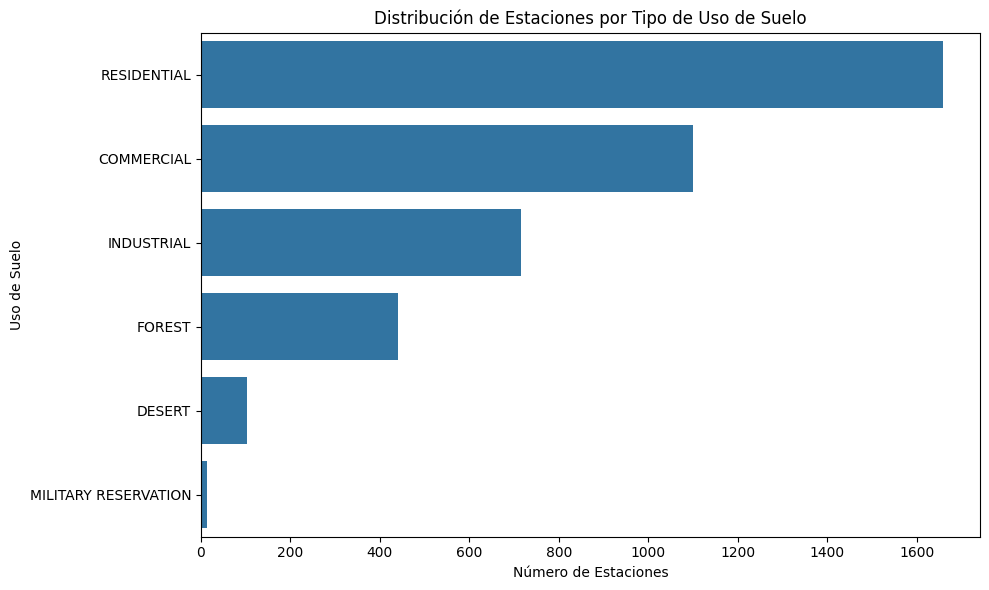

In [ ]:
print("\n--- Distribución de 'Land Use' ---")
plt.figure(figsize=(10, 6))
sns.countplot(data=station_index_table, y='Land Use', order=station_index_table['Land Use'].value_counts().index)
plt.title('Distribución de Estaciones por Tipo de Uso de Suelo')
plt.xlabel('Número de Estaciones')
plt.ylabel('Uso de Suelo')
plt.tight_layout()
plt.show()


--- Distribución de 'Location Setting' ---


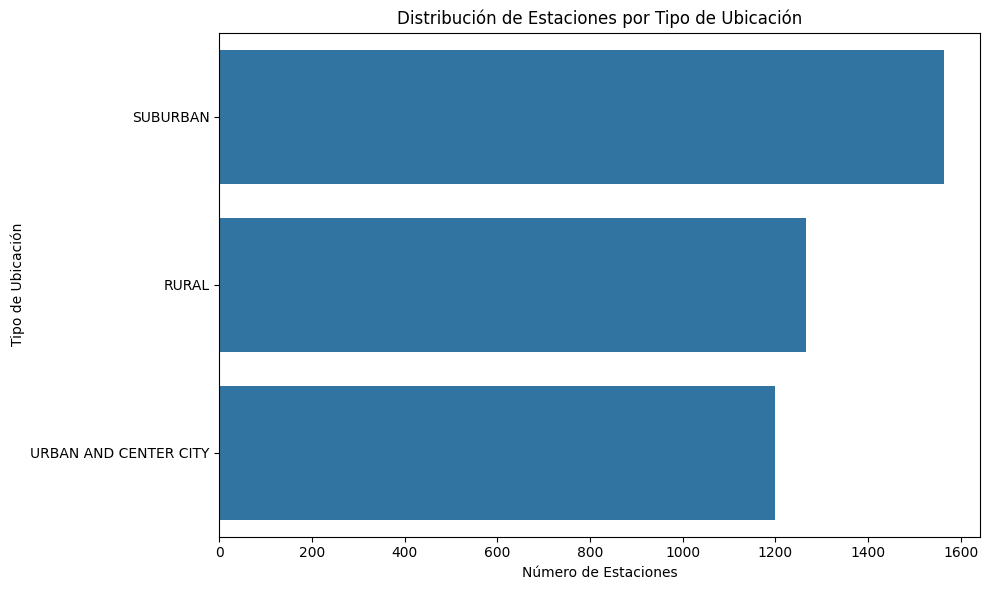

In [ ]:
print("\n--- Distribución de 'Location Setting' ---")
plt.figure(figsize=(10, 6))
sns.countplot(data=station_index_table, y='Location Setting', order=station_index_table['Location Setting'].value_counts().index)
plt.title('Distribución de Estaciones por Tipo de Ubicación')
plt.xlabel('Número de Estaciones')
plt.ylabel('Tipo de Ubicación')
plt.tight_layout()
plt.show()


--- Relación entre 'Land Use' y 'Location Setting' (Heatmap) ---


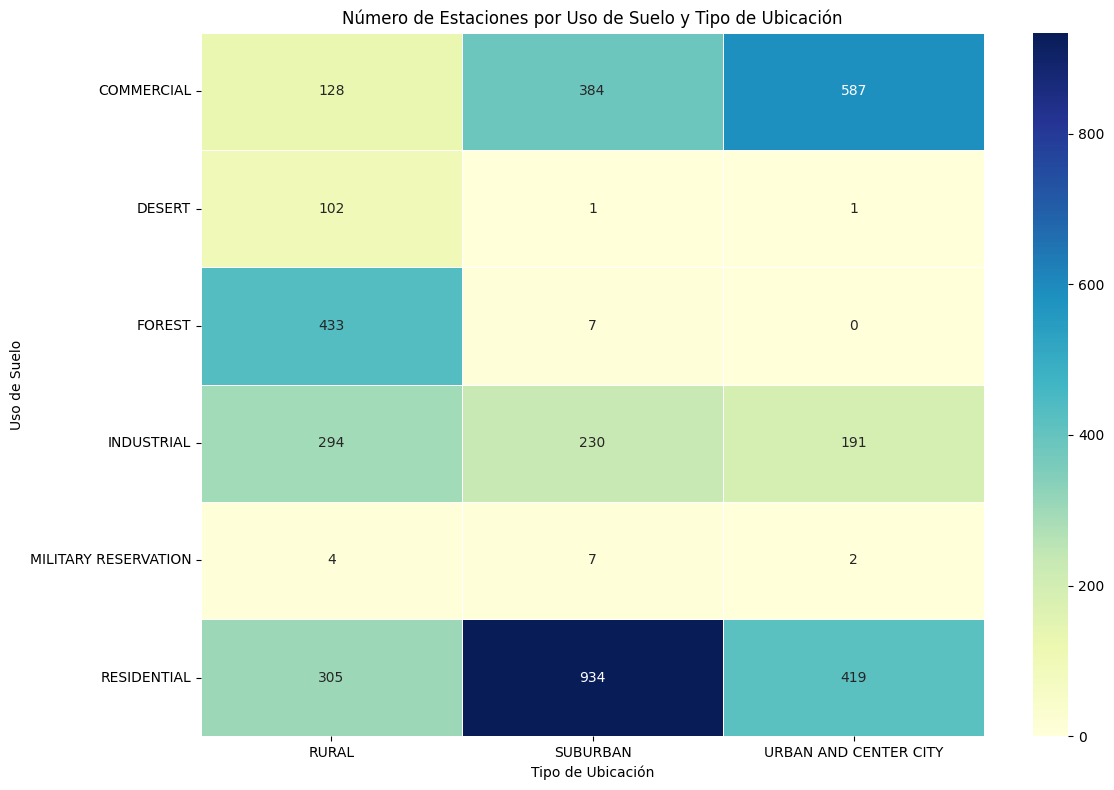

In [ ]:
print("\n--- Relación entre 'Land Use' y 'Location Setting' (Heatmap) ---")
plt.figure(figsize=(12, 8))
contingency_table = pd.crosstab(station_index_table['Land Use'], station_index_table['Location Setting'])
sns.heatmap(contingency_table, annot=True, fmt='d', cmap='YlGnBu', linewidths=.5)
plt.title('Número de Estaciones por Uso de Suelo y Tipo de Ubicación')
plt.xlabel('Tipo de Ubicación')
plt.ylabel('Uso de Suelo')
plt.tight_layout()
plt.show()


--- Distribución de Entropía (Histograma) ---


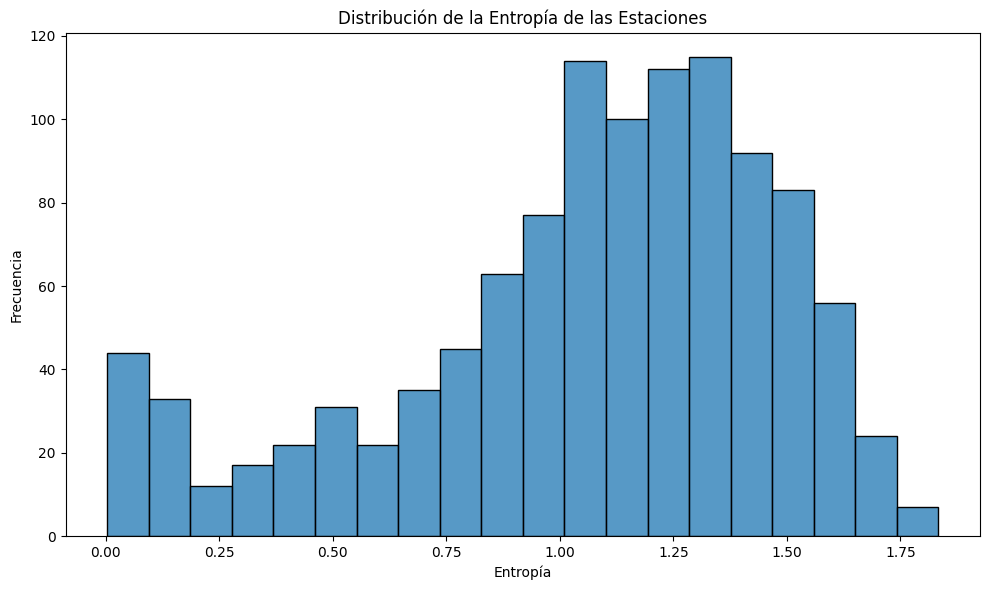

In [ ]:
print("\n--- Distribución de Entropía (Histograma) ---")
plt.figure(figsize=(10, 6))
sns.histplot(station_index_table_modified['Entropy'], kde=False, bins=20)
plt.title('Distribución de la Entropía de las Estaciones')
plt.xlabel('Entropía')
plt.ylabel('Frecuencia')
plt.tight_layout()
plt.show()



--- Distribución de Entropía (KDE Plot) ---


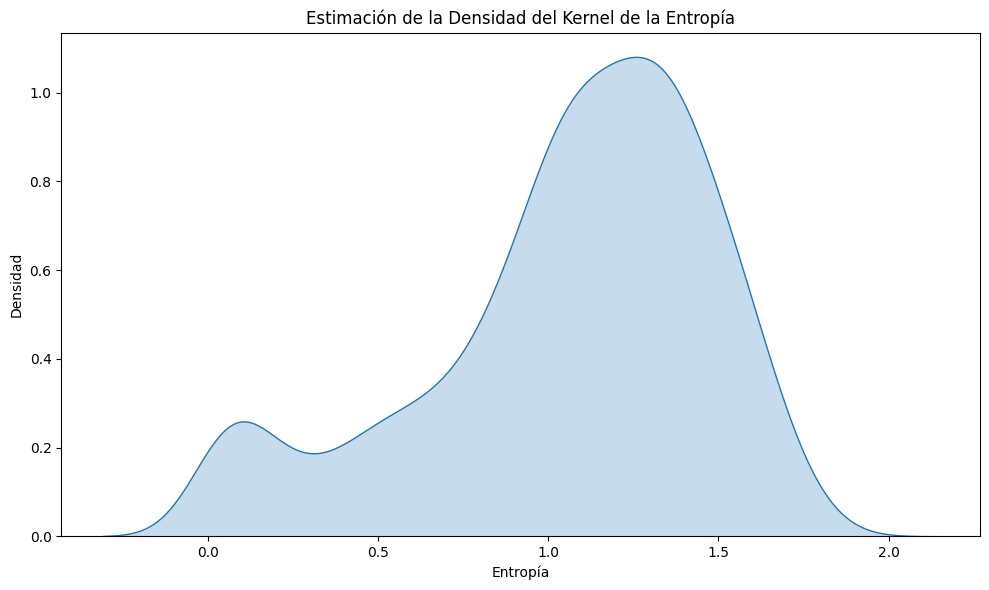

In [ ]:
print("\n--- Distribución de Entropía (KDE Plot) ---")
plt.figure(figsize=(10, 6))
sns.kdeplot(station_index_table_modified['Entropy'], fill=True)
plt.title('Estimación de la Densidad del Kernel de la Entropía')
plt.xlabel('Entropía')
plt.ylabel('Densidad')
plt.tight_layout()
plt.show()


--- Distribución de Latitud de las Estaciones (Histograma) ---


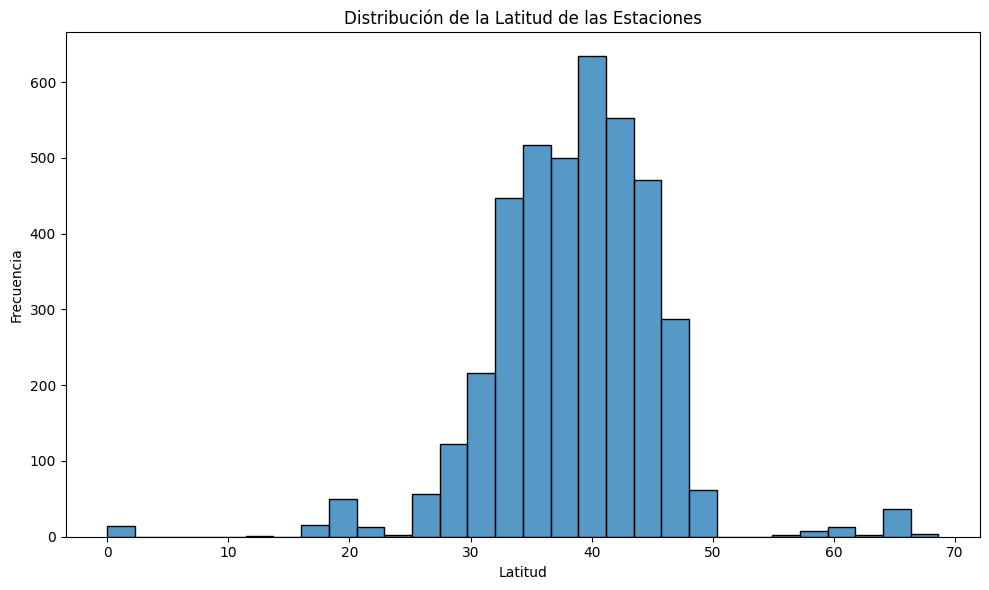

In [ ]:
print("\n--- Distribución de Latitud de las Estaciones (Histograma) ---")
plt.figure(figsize=(10, 6))
sns.histplot(station_index_table['Latitude'], kde=False, bins=30)
plt.title('Distribución de la Latitud de las Estaciones')
plt.xlabel('Latitud')
plt.ylabel('Frecuencia')
plt.tight_layout()
plt.show()


--- Distribución de 'Arithmetic Mean' por Contaminante (KDE Plot) ---


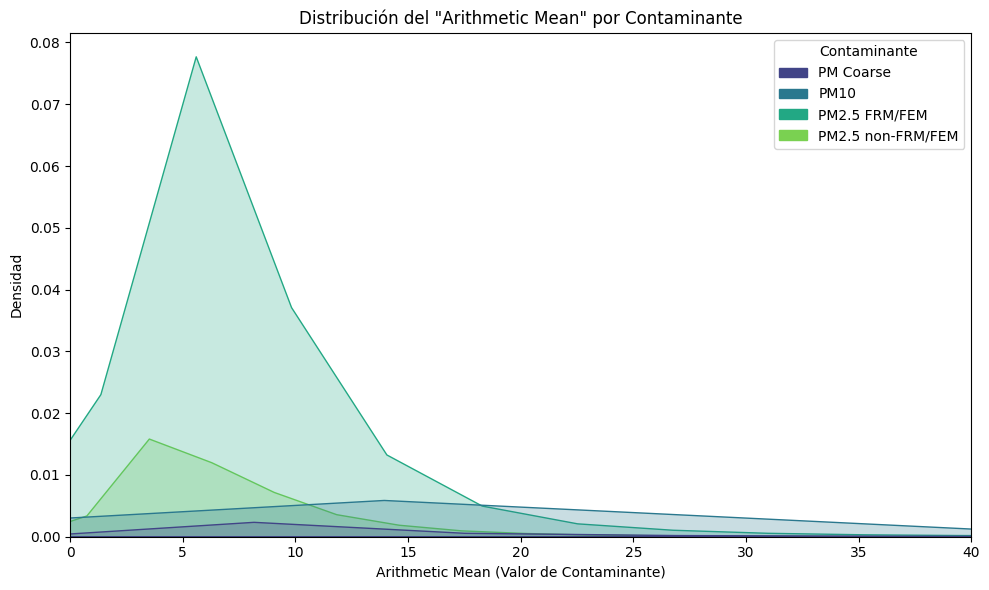

In [ ]:
import matplotlib.patches as mpatches

print("\n--- Distribución de 'Arithmetic Mean' por Contaminante (KDE Plot) ---")
plt.figure(figsize=(10, 6))
ax = sns.kdeplot(data=metadata_table, x='Arithmetic Mean', hue='Pollutant', fill=True, palette='viridis')

plt.title('Distribución del "Arithmetic Mean" por Contaminante')
plt.xlabel('Arithmetic Mean (Valor de Contaminante)')
plt.ylabel('Densidad')

# Establecer los límites del eje X de 0 a 100
plt.xlim(0, 40)

# Obtener los contaminantes únicos y crear parches de color para la leyenda
unique_pollutants = metadata_table['Pollutant'].unique()
colors = sns.color_palette('viridis', n_colors=len(unique_pollutants))

# Crear un mapeo de contaminante a color
color_map = dict(zip(unique_pollutants, colors))

# Crear handles de leyenda personalizados
legend_handles = [mpatches.Patch(color=color_map[p], label=p) for p in unique_pollutants]

# Añadir la leyenda personalizada al gráfico
ax.legend(handles=legend_handles, title='Contaminante', loc='upper right')

plt.tight_layout()
plt.show()


--- 'Arithmetic Mean' promedio por 'Location Setting' (Gráfico de Barras) ---


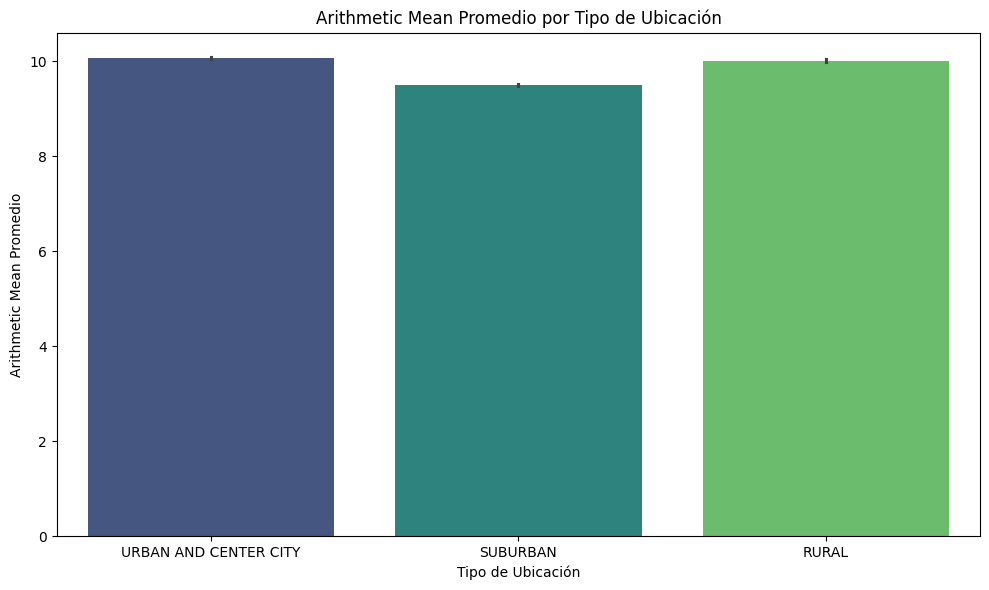

In [ ]:
print("\n--- 'Arithmetic Mean' promedio por 'Location Setting' (Gráfico de Barras) ---")
plt.figure(figsize=(10, 6))
sns.barplot(data=metadata_table, x='Location Setting', y='Arithmetic Mean', estimator=np.mean, hue='Location Setting', legend=False, palette='viridis')
plt.title('Arithmetic Mean Promedio por Tipo de Ubicación')
plt.xlabel('Tipo de Ubicación')
plt.ylabel('Arithmetic Mean Promedio')
plt.tight_layout()
plt.show()


--- 'Arithmetic Mean' promedio por 'Land Use' (Gráfico de Barras) ---


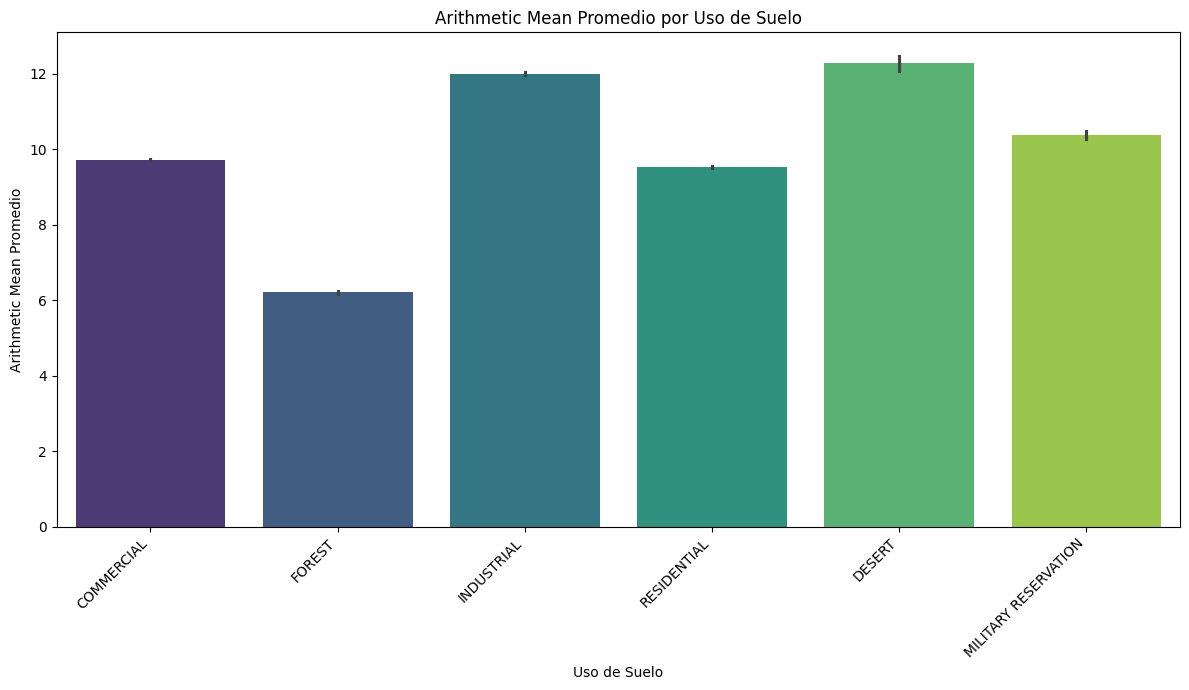

In [ ]:
print("\n--- 'Arithmetic Mean' promedio por 'Land Use' (Gráfico de Barras) ---")
plt.figure(figsize=(12, 7))
sns.barplot(data=metadata_table, x='Land Use', y='Arithmetic Mean', estimator=np.mean, hue='Land Use', legend=False, palette='viridis')
plt.title('Arithmetic Mean Promedio por Uso de Suelo')
plt.xlabel('Uso de Suelo')
plt.ylabel('Arithmetic Mean Promedio')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


--- Distribución de Entropía por 'Location Setting' (Gráfico de Cajas) ---


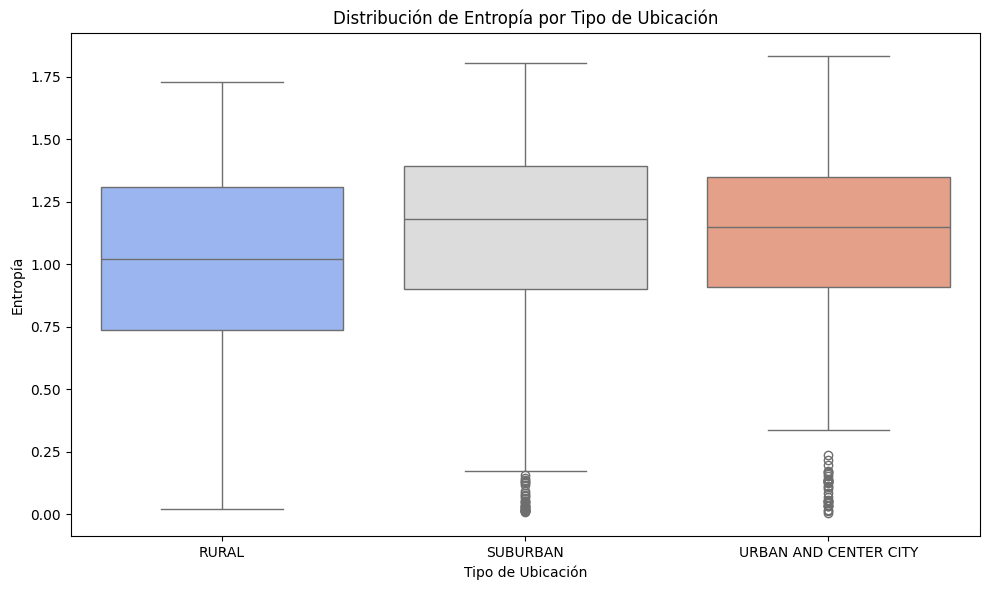

In [ ]:
print("\n--- Distribución de Entropía por 'Location Setting' (Gráfico de Cajas) ---")
plt.figure(figsize=(10, 6))
sns.boxplot(data=station_index_table_modified, x='Location Setting', y='Entropy', hue='Location Setting', legend=False, palette='coolwarm')
plt.title('Distribución de Entropía por Tipo de Ubicación')
plt.xlabel('Tipo de Ubicación')
plt.ylabel('Entropía')
plt.tight_layout()
plt.show()

In [ ]:
# Extensión para un análisis robusto orientado a paper

metadata_table["Year"] = metadata_table["Date Local"].dt.year


def mad(series):
    values = pd.Series(series).dropna().astype(float)
    if values.empty:
        return np.nan
    return float(np.median(np.abs(values - np.median(values))))


def bootstrap_ci(values, stat_fn=np.median, n_boot=2000, ci=95, random_state=42):
    values = pd.Series(values).dropna().astype(float).to_numpy()
    if len(values) == 0:
        return np.nan, np.nan, np.nan

    rng = np.random.default_rng(random_state)
    bootstrap_stats = np.empty(n_boot)

    for index in range(n_boot):
        sample = rng.choice(values, size=len(values), replace=True)
        bootstrap_stats[index] = stat_fn(sample)

    alpha = (100 - ci) / 2
    center = stat_fn(values)
    lower = np.percentile(bootstrap_stats, alpha)
    upper = np.percentile(bootstrap_stats, 100 - alpha)
    return center, lower, upper


def robust_summary(df, group_cols, value_col="Arithmetic Mean"):
    return (
        df.groupby(group_cols)[value_col]
        .agg(
            n="count",
            mean="mean",
            median="median",
            std="std",
            q25=lambda s: s.quantile(0.25),
            q75=lambda s: s.quantile(0.75),
            iqr=lambda s: s.quantile(0.75) - s.quantile(0.25),
            mad=mad,
            minimum="min",
            maximum="max",
        )
        .reset_index()
        .sort_values(group_cols)
        .reset_index(drop=True)
    )


station_season_year_summary = robust_summary(
    metadata_table,
    ["Pollutant", "Year", "season"],
)

pollutant_season_summary = robust_summary(
    metadata_table,
    ["Pollutant", "season"],
)

pollutant_location_summary = robust_summary(
    metadata_table,
    ["Pollutant", "Location Setting"],
)

pollutant_landuse_summary = robust_summary(
    metadata_table,
    ["Pollutant", "Land Use"],
)

entropy_location_summary = (
    station_index_table_modified.groupby("Location Setting")["Entropy"]
    .agg(
        n="count",
        mean="mean",
        median="median",
        std="std",
        q25=lambda s: s.quantile(0.25),
        q75=lambda s: s.quantile(0.75),
        iqr=lambda s: s.quantile(0.75) - s.quantile(0.25),
    )
    .reset_index()
)

print("=== Resumen robusto por contaminante, ano y temporada ===")
print(f"Filas: {len(station_season_year_summary):,}")
print(station_season_year_summary.head(12).to_string(index=False))

print("\n=== Resumen robusto por contaminante y temporada ===")
print(f"Filas: {len(pollutant_season_summary):,}")
print(pollutant_season_summary.head(12).to_string(index=False))

print("\n=== Entropia por tipo de ubicacion ===")
print(entropy_location_summary.to_string(index=False))

=== Resumen robusto por contaminante, ano y temporada ===
Filas: 48
Pollutant  Year season    n      mean   median       std      q25       q75       iqr      mad   minimum     maximum
PM Coarse  2023   Fall 8096 12.211705 8.666667 11.680087 5.178125 15.080208  9.902083 4.266667 -2.800000  249.291667
PM Coarse  2023 Spring 8051 10.655587 8.400000  9.936051 5.183333 13.250000  8.066667 3.754167 -3.875000  379.783333
PM Coarse  2023 Summer 8149 12.505664 9.633333 10.969239 6.620833 14.970833  8.350000 3.633334 -1.708333  297.025000
PM Coarse  2023 Winter 7670  9.090728 6.261685 10.915995 3.633333 10.562500  6.929167 3.095018 -6.063636  214.225000
PM Coarse  2024   Fall 8231 13.659195 8.850000 14.871741 5.202084 16.602083 11.400000 4.575000 -4.375000  331.229167
PM Coarse  2024 Spring 8412 10.033493 7.583333 12.165821 4.512500 12.066667  7.554167 3.520833 -2.350000  454.704167
PM Coarse  2024 Summer 8368 11.632545 8.800000 10.791271 6.416667 13.109375  6.692708 2.925000  0.100000  281.516

In [ ]:
# Contrastes robustos e intervalos de confianza por bootstrap

def bootstrap_group_summary(df, group_cols, value_col, stat_fn=np.median, n_boot=2000, ci=95):
    rows = []
    for keys, group in df.groupby(group_cols):
        if not isinstance(keys, tuple):
            keys = (keys,)
        center, lower, upper = bootstrap_ci(group[value_col], stat_fn=stat_fn, n_boot=n_boot, ci=ci)
        row = {group_cols[index]: keys[index] for index in range(len(group_cols))}
        row.update(
            {
                "n": group[value_col].dropna().shape[0],
                "center": center,
                "ci_lower": lower,
                "ci_upper": upper,
                "ci_width": upper - lower,
            }
        )
        rows.append(row)
    return pd.DataFrame(rows).sort_values(group_cols).reset_index(drop=True)


seasonal_bootstrap_summary = bootstrap_group_summary(
    metadata_table,
    ["Pollutant", "season"],
    "Arithmetic Mean",
)

location_bootstrap_summary = bootstrap_group_summary(
    metadata_table,
    ["Pollutant", "Location Setting"],
    "Arithmetic Mean",
)

landuse_bootstrap_summary = bootstrap_group_summary(
    metadata_table,
    ["Pollutant", "Land Use"],
    "Arithmetic Mean",
)

entropy_location_bootstrap = bootstrap_group_summary(
    station_index_table_modified,
    ["Location Setting"],
    "Entropy",
)

entropy_landuse_bootstrap = bootstrap_group_summary(
    station_index_table_modified,
    ["Land Use"],
    "Entropy",
)

print("=== Bootstrap medians por contaminante y temporada ===")
print(seasonal_bootstrap_summary.head(12).to_string(index=False))

print("\n=== Bootstrap medians por contaminante y location setting ===")
print(location_bootstrap_summary.head(12).to_string(index=False))

print("\n=== Bootstrap de entropia por location setting ===")
print(entropy_location_bootstrap.to_string(index=False))

=== Bootstrap medians por contaminante y temporada ===
    Pollutant season      n    center  ci_lower  ci_upper  ci_width
    PM Coarse   Fall  24134  8.504167  8.406202  8.612500  0.206298
    PM Coarse Spring  24669  7.875000  7.783333  7.970833  0.187500
    PM Coarse Summer  24686  9.129167  9.054167  9.200000  0.145833
    PM Coarse Winter  23576  6.575000  6.491667  6.654167  0.162500
         PM10   Fall 108073 17.000000 17.000000 17.000000  0.000000
         PM10 Spring 108152 16.000000 16.000000 16.000000  0.000000
         PM10 Summer 108426 20.000000 20.000000 20.000000  0.000000
         PM10 Winter 105936 13.000000 13.000000 13.000000  0.000000
PM2.5 FRM/FEM   Fall 478385  6.100000  6.083333  6.100000  0.016667
PM2.5 FRM/FEM Spring 517564  5.700000  5.700000  5.700000  0.000000
PM2.5 FRM/FEM Summer 504041  7.600000  7.600000  7.600000  0.000000
PM2.5 FRM/FEM Winter 491285  6.375000  6.337500  6.400000  0.062500

=== Bootstrap medians por contaminante y location setting ==

=== Matriz de correlacion Spearman entre contaminantes ===
Pollutant          PM2.5 FRM/FEM  PM2.5 non-FRM/FEM      PM10  PM Coarse
Pollutant                                                               
PM2.5 FRM/FEM           1.000000           0.896726  0.539301   0.491739
PM2.5 non-FRM/FEM       0.896726           1.000000  0.449724   1.000000
PM10                    0.539301           0.449724  1.000000   0.925705
PM Coarse               0.491739           1.000000  0.925705   1.000000

=== Medianas por estacion meteorologica y contaminante ===
Pollutant  PM Coarse  PM10  PM2.5 FRM/FEM  PM2.5 non-FRM/FEM
season                                                      
Winter      6.575000  13.0          6.375           6.225000
Spring      7.875000  16.0          5.700           4.528869
Summer      9.129167  20.0          7.600           6.100000
Fall        8.504167  17.0          6.100           6.100000


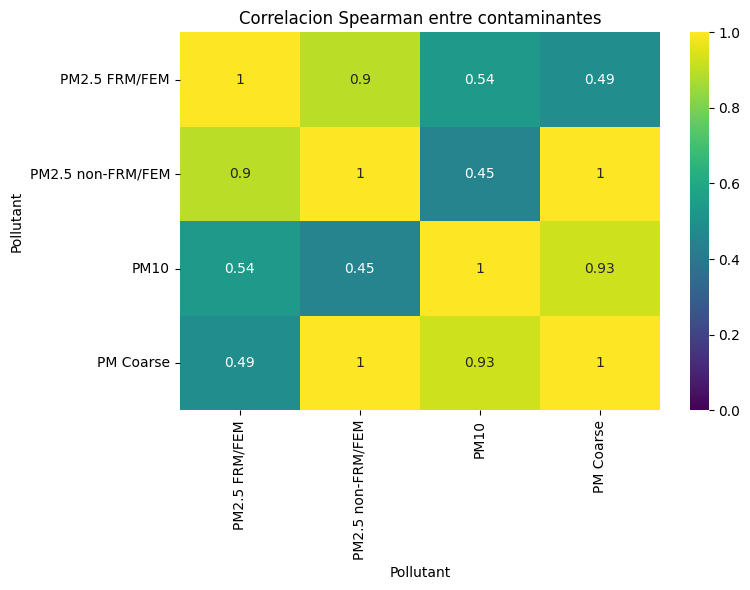

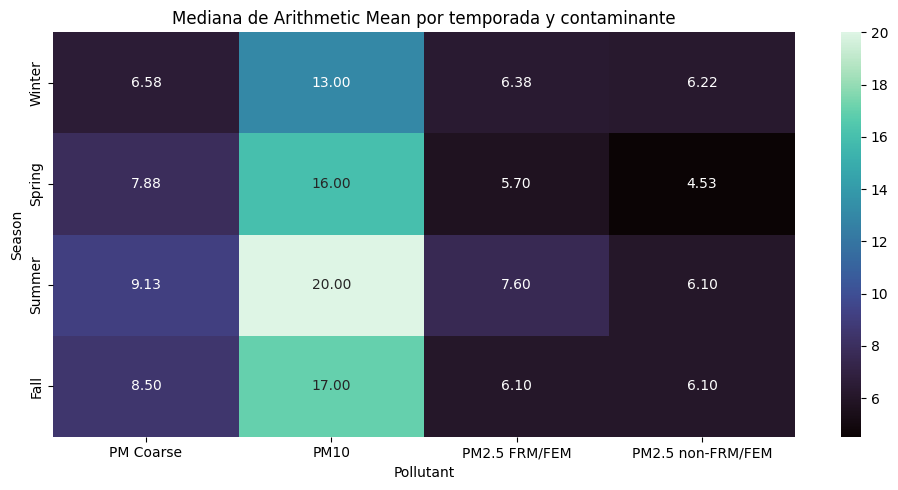

In [ ]:
# Relacion entre contaminantes y matriz estacional de mediana

station_pollutant_medians = (
    metadata_table.groupby(["Station ID", "season", "Pollutant"])["Arithmetic Mean"]
    .median()
    .unstack("Pollutant")
    .reset_index()
)

pollutant_correlation_matrix = (
    station_pollutant_medians[["PM2.5 FRM/FEM", "PM2.5 non-FRM/FEM", "PM10", "PM Coarse"]]
    .corr(method="spearman")
)

seasonal_median_matrix = (
    metadata_table.groupby(["season", "Pollutant"])["Arithmetic Mean"]
    .median()
    .unstack("Pollutant")
    .reindex(["Winter", "Spring", "Summer", "Fall"])
)

print("=== Matriz de correlacion Spearman entre contaminantes ===")
print(pollutant_correlation_matrix.to_string())

print("\n=== Medianas por estacion meteorologica y contaminante ===")
print(seasonal_median_matrix.to_string())

plt.figure(figsize=(8, 6))
sns.heatmap(pollutant_correlation_matrix, annot=True, cmap="viridis", vmin=0, vmax=1)
plt.title("Correlacion Spearman entre contaminantes")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
sns.heatmap(seasonal_median_matrix, annot=True, fmt=".2f", cmap="mako")
plt.title("Mediana de Arithmetic Mean por temporada y contaminante")
plt.ylabel("Season")
plt.tight_layout()
plt.show()

## Guia de redaccion para un paper

Con las tablas y graficas nuevas, el notebook ya permite redactar una seccion de Resultados con tres niveles:

1. Descripcion de cobertura y calidad de datos.
2. Comparacion robusta por temporada, tipo de ubicacion y uso de suelo.
3. Interpretacion de la entropia como señal de irregularidad temporal y no como indice fisico final de mezcla fino-grueso.

La lectura central que deja esta version es la siguiente:

- La estructura temporal de PM10 y PM Coarse esta fuertemente acoplada.
- PM2.5 FRM/FEM y PM2.5 non-FRM/FEM muestran alta similitud, pero no identidad.
- La estacionalidad afecta las medianas de todos los contaminantes, con verano y otono mas altos en PM grueso y PM10.
- La entropia separa parcialmente entornos rurales de suburbanos y urbanos, pero por si sola no define el regimen de mezcla.

Si se quiere llevar esto a nivel de articulo, la proxima capa deberia combinar estas salidas con una definicion operacional de fraccion fina, masa gruesa y un score no lineal robusto por estacion y temporada.

## Sección adicional: índice operacional robusto candidato

Esta sección está separada de la parte descriptiva para dejar una capa metodológica lista para un paper.

La idea aquí no es copiar el índice del artículo, sino construir un score funcional, racional y estable para comparar estaciones y temporadas entre periodos distintos.

Definición operacional propuesta:

- Fracción fina operativa: `PM2.5 FRM/FEM / PM10`
- Masa gruesa proxy: `PM10 - PM2.5 FRM/FEM`
- Score no lineal robusto: combinación logística de variables estandarizadas dentro de cada año

La normalización dentro de cada año evita que las diferencias de escala entre 2023, 2024 y 2025 contaminen la comparación entre temporadas.

In [ ]:
# Índice operacional robusto candidato por estación, año y temporada


def robust_zscore(series):
    values = pd.Series(series).astype(float)
    center = values.median()
    scale = mad(values)
    if pd.isna(scale) or scale == 0:
        scale = values.std(ddof=0)
    if pd.isna(scale) or scale == 0:
        return pd.Series(np.zeros(len(values)), index=values.index)
    return (values - center) / scale


def sigmoid(values):
    values = pd.Series(values).astype(float)
    return 1 / (1 + np.exp(-values))


operational_wide = (
    metadata_table.pivot_table(
        index=["Station ID", "Year", "season"],
        columns="Pollutant",
        values="Arithmetic Mean",
        aggfunc="median",
    )
    .reset_index()
)

coverage_days = (
    metadata_table.groupby(["Station ID", "Year", "season"])["Date Local"]
    .nunique()
    .rename("coverage_days")
    .reset_index()
)

operational_wide = operational_wide.merge(
    coverage_days,
    on=["Station ID", "Year", "season"],
    how="left",
)

operational_wide["fine_fraction"] = (
    operational_wide["PM2.5 FRM/FEM"] / operational_wide["PM10"]
).replace([np.inf, -np.inf], np.nan)
operational_wide["fine_fraction"] = operational_wide["fine_fraction"].clip(lower=0, upper=1)

operational_wide["coarse_mass_proxy"] = (
    operational_wide["PM10"] - operational_wide["PM2.5 FRM/FEM"]
).clip(lower=0)

operational_wide["coarse_ratio_proxy"] = (
    operational_wide["PM Coarse"] / operational_wide["PM10"]
).replace([np.inf, -np.inf], np.nan)

operational_wide["analysis_ready"] = (
    operational_wide[["PM2.5 FRM/FEM", "PM10"]].notna().all(axis=1)
    & (operational_wide["coverage_days"] >= 45)
)

score_input = operational_wide[operational_wide["analysis_ready"]].copy()
score_input["fine_fraction_z_year"] = score_input.groupby("Year")["fine_fraction"].transform(robust_zscore)
score_input["coarse_mass_z_year"] = score_input.groupby("Year")["coarse_mass_proxy"].transform(robust_zscore)
score_input["score_raw"] = (
    1.25 * score_input["fine_fraction_z_year"]
    - 1.00 * score_input["coarse_mass_z_year"]
)
score_input["candidate_score"] = sigmoid(score_input["score_raw"])

station_season_candidate_index = (
    score_input.groupby(["Station ID", "season"])
    .agg(
        candidate_score=("candidate_score", "median"),
        candidate_score_iqr=("candidate_score", lambda s: s.quantile(0.75) - s.quantile(0.25)),
        fine_fraction_median=("fine_fraction", "median"),
        coarse_mass_proxy_median=("coarse_mass_proxy", "median"),
        coarse_ratio_proxy_median=("coarse_ratio_proxy", "median"),
        coverage_days_median=("coverage_days", "median"),
        years_observed=("Year", "nunique"),
    )
    .reset_index()
)

station_season_candidate_index = station_season_candidate_index.merge(
    station_index_table_modified[["Station ID", "Land Use", "Location Setting", "Latitude", "Longitude", "Entropy"]],
    on="Station ID",
    how="left",
)

season_candidate_summary = (
    station_season_candidate_index.groupby("season")
    .agg(
        stations=("Station ID", "nunique"),
        candidate_score_median=("candidate_score", "median"),
        candidate_score_iqr=("candidate_score", lambda s: s.quantile(0.75) - s.quantile(0.25)),
        fine_fraction_median=("fine_fraction_median", "median"),
        coarse_mass_proxy_median=("coarse_mass_proxy_median", "median"),
        coverage_days_median=("coverage_days_median", "median"),
    )
    .reindex(["Winter", "Spring", "Summer", "Fall"])
    .reset_index()
)

location_candidate_summary = (
    station_season_candidate_index.groupby("Location Setting")
    .agg(
        stations=("Station ID", "nunique"),
        candidate_score_median=("candidate_score", "median"),
        candidate_score_iqr=("candidate_score", lambda s: s.quantile(0.75) - s.quantile(0.25)),
        entropy_median=("Entropy", "median"),
        fine_fraction_median=("fine_fraction_median", "median"),
        coarse_mass_proxy_median=("coarse_mass_proxy_median", "median"),
    )
    .reset_index()
)

year_candidate_summary = (
    score_input.groupby("Year")
    .agg(
        station_season_pairs=("Station ID", "nunique"),
        candidate_score_median=("candidate_score", "median"),
        fine_fraction_median=("fine_fraction", "median"),
        coarse_mass_proxy_median=("coarse_mass_proxy", "median"),
        coverage_days_median=("coverage_days", "median"),
    )
    .reset_index()
)

print("=== Candidate index by season ===")
print(season_candidate_summary.to_string(index=False))

print("\n=== Candidate index by year ===")
print(year_candidate_summary.to_string(index=False))

print("\n=== Candidate index by location setting ===")
print(location_candidate_summary.to_string(index=False))

print("\n=== Preview of station-season candidate index ===")
print(station_season_candidate_index.head(12).to_string(index=False))

=== Candidate index by season ===
season  stations  candidate_score_median  candidate_score_iqr  fine_fraction_median  coarse_mass_proxy_median  coverage_days_median
Winter       244                0.847917             0.695990              0.478888                  6.875000                  90.0
Spring       244                0.424162             0.702434              0.380078                  9.748959                  92.0
Summer       244                0.321950             0.740529              0.379008                 12.212054                  92.0
  Fall       244                0.266299             0.739086              0.368575                 11.129167                  91.0

=== Candidate index by year ===
 Year  station_season_pairs  candidate_score_median  fine_fraction_median  coarse_mass_proxy_median  coverage_days_median
 2023                   242                0.503886              0.406386                   9.90000                  91.0
 2024                   244  